# LLM-as-a-judge
A local LLM (qwen3.5:9b through Ollama, temperature 0) judged the topics of every dataset on four tasks:

- **rating:** how clearly a topic's top 10 words form one theme (1–3);
- **word intrusion:** find the one word that does not belong among six;
- **document intrusion:** find the one document that does not belong among four;
- **pair:** whether two topics are the same, overlap, or different.

Section 1 checks the judge against two human annotators before trusting it. Sections 2–5 use it.

In [1]:
import os
import sys
from itertools import combinations
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import cohen_kappa_score

if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, "scripts")

from llm_as_a_judge_validate import KEY_FILE, PAIR_SCALE, TASKS, read_annotators, read_cache

R = Path("results")
MODEL = "qwen3.5:9b"
summary = pd.read_csv(R / "llm_judge_summary.csv")
summary = summary[summary.model == MODEL].set_index("run")
main_runs = [r for r in summary.index if "noETP" not in r]
COLS = {"rating_mean": "mean rating", "rating_3_share": "share rated 3", "word_intrusion_acc": "word acc",
        "doc_intrusion_acc": "document acc", "redundant_similar_pairs": "same: similar pairs",
        "redundant_random_pairs": "same: random pairs", "unparsed": "unparsed"}
print(f"{len(main_runs)} datasets judged:", ", ".join(r.split("_K")[0] for r in main_runs))

13 datasets judged: 20NG, NYT, BBC, OHSUMED, TMDB, Guardian, Reuters, TREC-coarse, DBpedia, TREC-fine, Wikitext-103, NeurIPS, ACL


## 1. Can we trust the judge?
Two annotators answered 100 questions per task (400 in total, from 20NG, NYT, BBC, OHSUMED and TMDB) without seeing the LLM's answers. Cohen's $\kappa$ measures agreement corrected for chance:

$$\kappa = \frac{p_o - p_e}{1 - p_e}$$

where $p_o$ is the observed agreement and $p_e$ the agreement expected by chance. Rating and pair are ordered scales, so they use quadratic weights (a one-step miss counts partly). The judge is human-level on a task if its agreement with each annotator is close to the annotators' agreement with each other.

### 1.1. Agreement

In [2]:
key = pd.read_csv(KEY_FILE, dtype={"topic": str})

# The LLM's answer and the planted intruder (truth) for every question, matched on run, task and topic.
llm = []
for run in key.run.unique():
    for c in read_cache(run, MODEL):
        reply = c["reply"]
        llm.append({"run": run, "task": c["task"], "topic": str(c["topic"]),
                    "truth": str(c.get("answer", "")).strip().lower(),           # empty for rating and pair
                    "LLM": str(reply.get("rating", reply.get("intruder", reply.get("answer", "")))).strip().lower()})
table = key.merge(pd.DataFrame(llm), on=["run", "task", "topic"], how="left").set_index("id")

annotators = read_annotators()
for name, answers in annotators.items():
    table[name] = answers
raters = ["LLM"] + list(annotators)
table[raters] = table[raters].mask(table[raters] == "")                          # blank answer = not answered
def kappa(task, a, b):
    t = table.loc[table.task == task, [a, b]].dropna()                    # questions both answered
    if task == "pair":
        t = t.replace(PAIR_SCALE)                                         # different < overlap < same
    weights = "quadratic" if task in ("rating", "pair") else None
    return cohen_kappa_score(t[a], t[b], weights=weights)

pd.DataFrame({f"{a} vs {b}": {task: kappa(task, a, b) for task in TASKS}
              for a, b in combinations(raters, 2)}).round(3)

annotator_1: 400 answers from 4 files
annotator_2: 400 answers from 4 files


,LLM vs annotator_1,LLM vs annotator_2,annotator_1 vs annotator_2
rating,0.380,0.292,0.751
word,0.557,0.507,0.859
document,0.805,0.692,0.792
pair,0.110,0.148,0.619


### 1.2. Finding the planted intruder
Intrusion questions have a right answer, so each rater can also be scored.

In [3]:
intrusion = table[table.task.isin(["word", "document"])]
acc = pd.DataFrame({r: intrusion.groupby("task").apply(lambda t: (t[r] == t.truth)[t[r].notna()].mean(),
                                                       include_groups=False) for r in raters})
acc.round(3)

,LLM,annotator_1,annotator_2
task,,,
document,0.888,0.97,0.88
word,0.500,0.78,0.87


### 1.3. Where the judge disagrees
Rows are annotator 1's answers, columns the LLM's.

In [4]:
for task in ["rating", "pair"]:
    t = table[table.task == task]
    print(task)
    display(pd.crosstab(t.annotator_1, t.LLM))

rating


LLM,1,2,3
annotator_1,,,
1,3,4,6
2,3,5,20
3,1,2,56


pair


LLM,different,overlap
annotator_1,,
different,54,2
overlap,38,6


**Conclusion:**
- **Document intrusion is human-level.** $\kappa$ = 0.69–0.81 with the annotators vs 0.79 between them; accuracy 0.89 vs 0.88–0.97.
- **Word intrusion is not.** The LLM finds 0.50 of the intruders, the annotators 0.78–0.87, so the questions are fair but the judge misses half.
- **Ratings are too generous.** The LLM gives 3 to 82 of 100 topics, including 20 that annotator 1 rated 2 ($\kappa$ = 0.29–0.38 vs 0.75).
- **Pairs are too strict.** The LLM calls 92 of 100 pairs "different", including 38 that annotator 1 saw as overlapping ($\kappa$ = 0.11–0.15 vs 0.62).

So only document intrusion is used as a trusted result below; the other tasks are reported as indicative.

## 2. Judge results by dataset ($K = 50$, seed 0)

In [5]:
summary.loc[main_runs, list(COLS)].rename(columns=COLS).round(3)

,mean rating,share rated 3,word acc,document acc,same: similar pairs,same: random pairs,unparsed
run,,,,,,,
20NG_K50_seed0,2.68,0.78,0.455,0.928,0.000,0.00,2
NYT_K50_seed0,2.82,0.88,0.566,0.935,0.000,0.00,2
BBC_K50_seed0,2.76,0.80,0.545,0.902,0.000,0.00,5
OHSUMED_K50_seed0,2.92,0.94,0.610,0.927,0.000,0.00,0
TMDB_K50_seed0,2.48,0.66,0.378,0.632,0.000,0.00,3
Guardian_K50_seed0,2.84,0.86,0.690,0.948,0.033,0.00,0
Reuters_K50_seed0,2.16,0.48,0.374,0.904,0.200,0.00,4
TREC-coarse_K50_seed0,2.94,0.94,0.134,0.341,1.000,0.75,2
DBpedia_K50_seed0,2.60,0.76,0.619,1.000,0.167,0.00,4


**Notes:**
- Document intrusion (the validated task) is 0.90–1.00 on most datasets. It is lower where documents are short or informal: TMDB reviews 0.63, TREC questions 0.34. A 4-word question gives the judge little to compare.
- The ratings repeat the generosity found in Section 1. TREC-coarse gets the highest mean rating (2.94) although its TD is 0.099, meaning its topics are near-copies of each other. Each copy is a coherent word list, so it rates well. Rating alone cannot catch redundant topics.
- Redundancy shows up in the pair task. The judge calls every similar TREC pair "same" (1.00) and 75% of random pairs. On the other datasets it calls almost none "same", apart from Reuters (0.20) and DBpedia (0.17).
- Unparsed replies are rare: at most 5 per dataset.

## 3. Position bias
Intrusion and pair questions were asked twice, with the options in a different order. The table shows the share of questions that got the same answer both times; 1.0 means the order made no difference.

In [6]:
ORDER = {"word_order_consistency": "word", "doc_order_consistency": "document", "pair_order_consistency": "pair"}
summary.loc[main_runs, list(ORDER)].rename(columns=ORDER).round(3)

,word,document,pair
run,,,
20NG_K50_seed0,0.469,0.854,0.88
NYT_K50_seed0,0.571,0.935,1.00
BBC_K50_seed0,0.429,0.867,0.92
OHSUMED_K50_seed0,0.520,0.896,0.92
TMDB_K50_seed0,0.333,0.535,0.92
Guardian_K50_seed0,0.560,0.896,0.92
Reuters_K50_seed0,0.449,0.925,1.00
TREC-coarse_K50_seed0,0.250,0.450,0.96
DBpedia_K50_seed0,0.489,1.000,0.92


**Notes:** Word intrusion depends strongly on the order of the options: only 25–64% of answers stay the same when the six words are shuffled, which matches its weak result against humans. Document intrusion is more stable (85–100% on most datasets) but drops where it was also inaccurate (TMDB 54%, TREC 45%). Pair answers barely change (88–100%) when A and B are swapped.

## 4. With and without ETP
The same datasets judged with FASTopic's ETP and with the softmax used in the replication's ablation ($\tau = 1$).

In [7]:
BASES = ["20NG", "NYT", "Wikitext-103"]
runs = [r for b in BASES for r in (f"{b}_K50_seed0", f"{b}-noETP_K50_seed0") if r in summary.index]
summary.loc[runs, list(COLS)].rename(columns=COLS).round(3)

,mean rating,share rated 3,word acc,document acc,same: similar pairs,same: random pairs,unparsed
run,,,,,,,
20NG_K50_seed0,2.68,0.78,0.455,0.928,0.000,0.00,2
20NG-noETP_K50_seed0,2.78,0.86,0.418,0.972,0.933,0.05,2
NYT_K50_seed0,2.82,0.88,0.566,0.935,0.000,0.00,2
NYT-noETP_K50_seed0,2.44,0.70,0.400,0.917,0.733,0.05,0
Wikitext-103_K50_seed0,2.92,0.92,0.730,0.923,0.000,0.00,1
Wikitext-103-noETP_K50_seed0,2.00,0.46,0.469,0.800,0.933,0.15,4


**Notes:** Without ETP, the judge calls 73–93% of the most similar topic pairs "the same", against none with ETP. Section 1 showed the judge leans towards "different" (it called 38 overlapping pairs different), so its errors make it less likely to say "same", not more; when it does, the topics are clearly redundant. This agrees with the TD drop without ETP in the replication notebook (Section 2) and supports the paper's claim that ETP prevents topic collapse. Ratings fall on NYT (2.82 → 2.44) and Wikitext-103 (2.92 → 2.00) but not on 20NG, consistent with ratings not detecting redundancy.

## 5. Document intrusion across datasets
The one validated metric. The shaded band is the two annotators' range on the validated datasets.

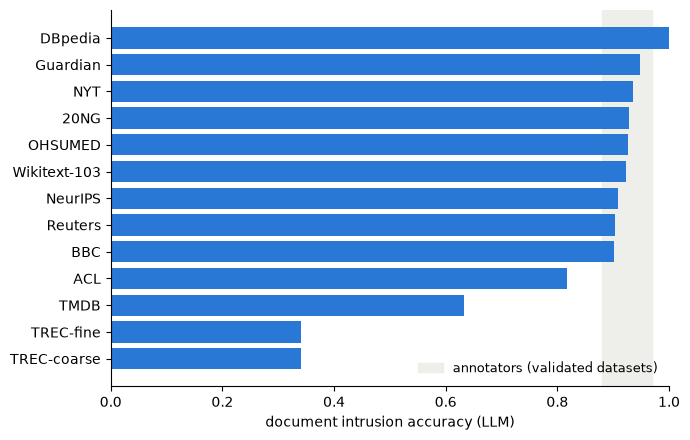

In [8]:
human = acc.loc["document", raters[1:]]
doc = summary.loc[main_runs, "doc_intrusion_acc"].sort_values()
doc.index = [r.split("_K")[0] for r in doc.index]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.axvspan(human.min(), human.max(), color="#eeeeea", label="annotators (validated datasets)")
ax.barh(doc.index, doc.values, color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel("document intrusion accuracy (LLM)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=9, loc="lower right")
fig.tight_layout()

**Notes:** On 10 of 13 datasets the judge's document intrusion accuracy is 0.82–1.00, close to or within the annotators' range, so FASTopic's topics match their documents. The exceptions are datasets with short texts: TMDB (0.63) and the two TREC sets (0.34).